# DeepGuard – Full-data, 5-seed, Ablation, Adversarial & Federated experiments
**Datasets:** NSL-KDD+ (KDDTrain+ / KDDTest+) and UNSW-NB15 (partitioned training-set / testing-set CSV)

**Before running**
1. `Runtime → Change runtime type → T4 GPU`
2. Put these 4 files in Google Drive folder `MyDrive/DeepGuard/data/` (sub-folders are fine):
   `KDDTrain+.txt`, `KDDTest+.txt`, `UNSW_NB15_training-set.csv`, `UNSW_NB15_testing-set.csv`
3. FIRST run once with `QUICK = True` (Cell 2) to check everything works (~10 min). Then set `QUICK = False` for the real run.

Results are saved per (dataset, seed) in Drive, so if Colab disconnects, just re-run all cells – finished seeds are skipped.

In [ ]:
# ===== Cell 1: setup =====
%pip -q install shap imbalanced-learn
import os, glob, json, time, copy, random, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             matthews_corrcoef, roc_auc_score, f1_score, confusion_matrix)
warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/DeepGuard/data"
BASE_OUT = "/content/drive/MyDrive/DeepGuard/results"

def find_file(patterns):
    for p in patterns:
        hits = glob.glob(os.path.join(DATA_DIR, "**", p), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(f"Not found in {DATA_DIR}: {patterns}")

PATHS = {
    "nsl_train": find_file(["KDDTrain+.txt", "KDDTrain+"]),
    "nsl_test":  find_file(["KDDTest+.txt", "KDDTest+"]),
    "unsw_train": find_file(["UNSW_NB15_training-set.csv"]),
    "unsw_test":  find_file(["UNSW_NB15_testing-set.csv"]),
}
for k, v in PATHS.items(): print(k, "->", v)

Device: cuda
Mounted at /content/drive
nsl_train -> /content/drive/MyDrive/DeepGuard/data/KDDTrain+.txt
nsl_test -> /content/drive/MyDrive/DeepGuard/data/KDDTest+.txt
unsw_train -> /content/drive/MyDrive/DeepGuard/data/UNSW_NB15_training-set.csv
unsw_test -> /content/drive/MyDrive/DeepGuard/data/UNSW_NB15_testing-set.csv


In [ ]:
# ===== Cell 2: configuration =====
QUICK = False          # <-- True = fast smoke test. Set False for the real full run.

SEEDS        = [42, 43, 44, 45, 46]
EPOCHS       = 15          # paper used 5-12 on CPU subsample; full data on GPU -> 15
BATCH        = 512
LR           = 2e-3
FED_CLIENTS  = 5
FED_ROUNDS   = 20
FED_BATCH    = 256
ADV_EPS      = [0.0, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20]
ADV_TRAIN_EPS, ADV_FT_EPOCHS, ADV_FT_LR = 0.05, 2, 1e-3
GAN_ITERS    = 3000
AUG_TARGET   = 3000        # minority classes are raised to this many training samples
TRAIN_CAP    = None
RUN_SHAP     = True
SEEDS = [42,43,44]
if QUICK:
    SEEDS, EPOCHS, FED_ROUNDS, GAN_ITERS, TRAIN_CAP = [42], 2, 3, 300, 20000

OUT = os.path.join(BASE_OUT, "quick" if QUICK else "full")
os.makedirs(OUT, exist_ok=True)
print("QUICK =", QUICK, "| seeds:", SEEDS, "| results ->", OUT)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

QUICK = False | seeds: [42, 43, 44] | results -> /content/drive/MyDrive/DeepGuard/results/full


In [ ]:
# ===== Cell 3: load + preprocess both datasets =====
NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment",
 "urgent","hot","num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root",
 "num_file_creations","num_shells","num_access_files","num_outbound_cmds","is_host_login","is_guest_login",
 "count","srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate",
 "diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate",
 "dst_host_diff_srv_rate","dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
 "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]

_groups = {
 "DoS":   "back land neptune pod smurf teardrop apache2 udpstorm processtable mailbomb worm",
 "Probe": "ipsweep nmap portsweep satan mscan saint",
 "R2L":   "ftp_write guess_passwd imap multihop phf spy warezclient warezmaster sendmail named snmpgetattack snmpguess xlock xsnoop httptunnel",
 "U2R":   "buffer_overflow loadmodule perl rootkit ps sqlattack xterm",
}
ATTACK_MAP = {"normal": "Normal"}
for g, names in _groups.items():
    for n in names.split(): ATTACK_MAP[n] = g

def encode_and_scale(Xtr_df, Xte_df, cat_cols):
    Xtr_df, Xte_df = Xtr_df.copy(), Xte_df.copy()
    for c in cat_cols:   # label-encode, fit on union of train+test categories (paper Sec 4.1)
        cats = sorted(set(Xtr_df[c].astype(str)) | set(Xte_df[c].astype(str)))
        m = {v: i for i, v in enumerate(cats)}
        Xtr_df[c] = Xtr_df[c].astype(str).map(m)
        Xte_df[c] = Xte_df[c].astype(str).map(m)
    Xtr = Xtr_df.fillna(0).values.astype(np.float32)
    Xte = Xte_df.fillna(0).values.astype(np.float32)
    sc = StandardScaler().fit(Xtr)                      # fit on train only (paper Sec 4.2)
    return sc.transform(Xtr).astype(np.float32), sc.transform(Xte).astype(np.float32), list(Xtr_df.columns)

def finish(name, Xtr, Xte, ytr_names, yte_names, classes, feats, minority):
    c2i = {c: i for i, c in enumerate(classes)}
    ytr = np.array([c2i[c] for c in ytr_names], dtype=np.int64)
    yte = np.array([c2i[c] for c in yte_names], dtype=np.int64)
    if TRAIN_CAP and len(ytr) > TRAIN_CAP:
        idx, _ = train_test_split(np.arange(len(ytr)), train_size=TRAIN_CAP, stratify=ytr, random_state=0)
        Xtr, ytr = Xtr[idx], ytr[idx]
    print(f"{name}: train {Xtr.shape}, test {Xte.shape}, features={len(feats)}")
    print("  train class counts:", dict(zip(classes, np.bincount(ytr, minlength=len(classes)).tolist())))
    print("  test  class counts:", dict(zip(classes, np.bincount(yte, minlength=len(classes)).tolist())))
    return dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, classes=classes, features=feats, minority=minority)

def load_nsl():
    tr = pd.read_csv(PATHS["nsl_train"], header=None); te = pd.read_csv(PATHS["nsl_test"], header=None)
    cols = NSL_COLS if tr.shape[1] == 43 else NSL_COLS[:-1]
    tr.columns, te.columns = cols, cols
    def lab(d):
        y = d["label"].astype(str).str.strip().str.lower().str.rstrip(".").map(ATTACK_MAP)
        assert y.notna().all(), f"Unmapped labels: {d['label'][y.isna()].unique()}"
        return y.values
    ytr, yte = lab(tr), lab(te)
    drop = [c for c in ["label", "difficulty"] if c in tr.columns]
    Xtr, Xte, feats = encode_and_scale(tr.drop(columns=drop), te.drop(columns=drop),
                                       ["protocol_type", "service", "flag"])
    return finish("NSL-KDD+", Xtr, Xte, ytr, yte, ["Normal","DoS","Probe","R2L","U2R"], feats, ["R2L","U2R"])

def load_unsw():
    tr = pd.read_csv(PATHS["unsw_train"]); te = pd.read_csv(PATHS["unsw_test"])
    tr.columns = [c.strip().lower() for c in tr.columns]; te.columns = [c.strip().lower() for c in te.columns]
    def lab(d):
        return d["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "nan": "Normal"}).values
    ytr, yte = lab(tr), lab(te)
    drop = [c for c in ["id", "attack_cat", "label"] if c in tr.columns]
    Xtr, Xte, feats = encode_and_scale(tr.drop(columns=drop), te.drop(columns=drop), ["proto", "service", "state"])
    classes = sorted(set(ytr) | set(yte))
    return finish("UNSW-NB15", Xtr, Xte, ytr, yte, classes, feats, ["Analysis","Backdoor","Shellcode","Worms"])

DATA = {"NSL-KDD+": load_nsl(), "UNSW-NB15": load_unsw()}

NSL-KDD+: train (125973, 41), test (22544, 41), features=41
  train class counts: {'Normal': 67343, 'DoS': 45927, 'Probe': 11656, 'R2L': 995, 'U2R': 52}
  test  class counts: {'Normal': 9711, 'DoS': 7460, 'Probe': 2421, 'R2L': 2885, 'U2R': 67}
UNSW-NB15: train (175341, 42), test (82332, 42), features=42
  train class counts: {'Analysis': 2000, 'Backdoor': 1746, 'DoS': 12264, 'Exploits': 33393, 'Fuzzers': 18184, 'Generic': 40000, 'Normal': 56000, 'Reconnaissance': 10491, 'Shellcode': 1133, 'Worms': 130}
  test  class counts: {'Analysis': 677, 'Backdoor': 583, 'DoS': 4089, 'Exploits': 11132, 'Fuzzers': 6062, 'Generic': 18871, 'Normal': 37000, 'Reconnaissance': 3496, 'Shellcode': 378, 'Worms': 44}


In [ ]:
# ===== Cell 4: model, metrics, training utilities =====
class DeepGuard(nn.Module):
    """1-D CNN (16/32/64, dilation 1/2/2, residual) -> BiLSTM(24x2) -> 4-head MHSA + LN -> mean pool -> FC(48-64-C)."""
    def __init__(self, n_classes):
        super().__init__()
        self.c1 = nn.Conv1d(1, 16, 3, padding=1, dilation=1)
        self.c2 = nn.Conv1d(16, 32, 3, padding=2, dilation=2); self.b2 = nn.BatchNorm1d(32)
        self.c3 = nn.Conv1d(32, 64, 3, padding=2, dilation=2); self.b3 = nn.BatchNorm1d(64)
        self.proj = nn.Conv1d(16, 64, 1)
        self.lstm = nn.LSTM(64, 24, batch_first=True, bidirectional=True)
        self.attn = nn.MultiheadAttention(48, 4, batch_first=True)
        self.ln = nn.LayerNorm(48)
        self.fc1 = nn.Linear(48, 64); self.drop = nn.Dropout(0.3); self.fc2 = nn.Linear(64, n_classes)
    def forward(self, x):
        x = x.unsqueeze(1)
        h1 = F.relu(self.c1(x))
        h2 = F.relu(self.b2(self.c2(h1)))
        h3 = F.relu(self.b3(self.c3(h2) + self.proj(h1)))
        h, _ = self.lstm(h3.transpose(1, 2))
        a, _ = self.attn(h, h, h)
        z = self.ln(h + a).mean(1)
        return self.fc2(self.drop(F.relu(self.fc1(z))))

print("Trainable parameters (C=5):", sum(p.numel() for p in DeepGuard(5).parameters() if p.requires_grad))

def class_weights(y, C):   # inverse-log-frequency weights (Sec 4.5), normalised to mean 1
    cnt = np.bincount(y, minlength=C).astype(float)
    w = 1.0 / np.log(1.1 + cnt)
    return torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE)

def batches(X, y, bs, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j], y[j]

def train_model(model, X, y, epochs, lr=LR, w=None, bs=BATCH, tag="", verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train(); tot = 0.0; n = 0
        for xb, yb in batches(X, y, bs):
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb, weight=w)
            loss.backward(); opt.step()
            tot += loss.item() * len(xb); n += len(xb)
        if verbose and (ep == 0 or (ep + 1) % 5 == 0 or ep == epochs - 1):
            print(f"    [{tag}] epoch {ep+1}/{epochs} loss={tot/n:.4f}")
    return model

@torch.no_grad()
def predict_proba(model, X, bs=4096):
    model.eval()
    return torch.cat([F.softmax(model(X[i:i + bs]), 1) for i in range(0, len(X), bs)]).cpu().numpy()

def macro_auc(y, S, C):
    aucs = []
    for c in range(C):
        yb = (y == c).astype(int)
        if 0 < yb.sum() < len(yb):
            aucs.append(roc_auc_score(yb, S[:, c]))
    return float(np.mean(aucs))

def evaluate(y, pred, S, C):
    L = list(range(C))
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=L, average="macro", zero_division=0)
    pcp, pcr, pcf, _ = precision_recall_fscore_support(y, pred, labels=L, average=None, zero_division=0)
    return dict(accuracy=float(accuracy_score(y, pred)), macro_precision=float(p), macro_recall=float(r),
                macro_f1=float(f), mcc=float(matthews_corrcoef(y, pred)), macro_auc=macro_auc(y, S, C),
                per_class_precision=pcp.tolist(), per_class_recall=pcr.tolist(), per_class_f1=pcf.tolist())

Trainable parameters (C=5): 39365


In [ ]:
# ===== Cell 5: cWGAN-GP + SMOTE augmentation =====
ZD, ED = 16, 8
class Gen(nn.Module):
    def __init__(self, nf, nc):
        super().__init__()
        self.emb = nn.Embedding(nc, ED)
        self.net = nn.Sequential(nn.Linear(ZD + ED, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, nf))
    def forward(self, z, c): return self.net(torch.cat([z, self.emb(c)], 1))

class Critic(nn.Module):
    def __init__(self, nf, nc):
        super().__init__()
        self.emb = nn.Embedding(nc, ED)
        self.net = nn.Sequential(nn.Linear(nf + ED, 128), nn.LeakyReLU(0.2), nn.Linear(128, 128), nn.LeakyReLU(0.2), nn.Linear(128, 1))
    def forward(self, x, c): return self.net(torch.cat([x, self.emb(c)], 1))

def gradient_penalty(D, real, fake, c):
    a = torch.rand(len(real), 1, device=DEVICE)
    xh = (a * real + (1 - a) * fake).requires_grad_(True)
    g = torch.autograd.grad(D(xh, c).sum(), xh, create_graph=True)[0]
    return ((g.norm(2, dim=1) - 1) ** 2).mean()

def train_cwgan(Xm, ym, nf, nc, min_ids, iters, bs=64, lam=10.0, n_critic=3):
    G, D = Gen(nf, nc).to(DEVICE), Critic(nf, nc).to(DEVICE)
    oG = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.5, 0.9))
    oD = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.9))
    pools = {c: torch.where(ym == c)[0] for c in min_ids}
    per = max(1, bs // len(min_ids))
    def sample_real():   # class-balanced mini-batch so rare classes are learnt too
        idx, cl = [], []
        for c, pool in pools.items():
            idx.append(pool[torch.randint(len(pool), (per,), device=DEVICE)]); cl.append(torch.full((per,), c, device=DEVICE))
        return Xm[torch.cat(idx)], torch.cat(cl).long()
    for it in range(iters):
        for _ in range(n_critic):
            real, c = sample_real()
            fake = G(torch.randn(len(real), ZD, device=DEVICE), c).detach()
            lossD = D(fake, c).mean() - D(real, c).mean() + lam * gradient_penalty(D, real, fake, c)
            oD.zero_grad(); lossD.backward(); oD.step()
        real, c = sample_real()
        lossG = -D(G(torch.randn(len(real), ZD, device=DEVICE), c), c).mean()
        oG.zero_grad(); lossG.backward(); oG.step()
        if it % 1000 == 0 or it == iters - 1:
            print(f"    [cWGAN-GP] it {it}: critic={lossD.item():.3f} gen={lossG.item():.3f}")
    return G

def gan_aug(X, y, min_ids, C, seed):
    set_seed(seed)
    m = np.isin(y, min_ids)
    Xm, ym = torch.tensor(X[m], device=DEVICE), torch.tensor(y[m], device=DEVICE)
    G = train_cwgan(Xm, ym, X.shape[1], C, min_ids, GAN_ITERS)
    cnt = np.bincount(y, minlength=C); Xn, yn = [X], [y]
    for c in min_ids:
        need = int(AUG_TARGET - cnt[c])
        if need > 0:
            with torch.no_grad():
                g = G(torch.randn(need, ZD, device=DEVICE), torch.full((need,), int(c), device=DEVICE, dtype=torch.long))
            Xn.append(g.cpu().numpy().astype(np.float32)); yn.append(np.full(need, c, dtype=np.int64))
    return np.concatenate(Xn), np.concatenate(yn)

def smote_aug(X, y, min_ids, C, seed):
    from imblearn.over_sampling import SMOTE
    cnt = np.bincount(y, minlength=C)
    strat = {int(c): AUG_TARGET for c in min_ids if cnt[c] < AUG_TARGET}
    if not strat: return X, y
    k = max(1, min(5, int(min(cnt[c] for c in strat)) - 1))
    Xr, yr = SMOTE(sampling_strategy=strat, k_neighbors=k, random_state=seed).fit_resample(X, y)
    return Xr.astype(np.float32), yr.astype(np.int64)

In [ ]:
# ===== Cell 6: FGSM adversarial evaluation / fine-tuning + FedAvg =====
def fgsm(model, x, y, eps):
    x = x.clone().detach().requires_grad_(True)
    with torch.backends.cudnn.flags(enabled=False):   # cuDNN RNN backward is not allowed in eval mode
        loss = F.cross_entropy(model(x), y)
        g, = torch.autograd.grad(loss, x)
    return (x + eps * g.sign()).detach()

def adv_eval(model, X, y_t, y_np, C, eps_list, bs=2048):
    model.eval(); res = {}
    for eps in eps_list:
        preds = []
        for i in range(0, len(X), bs):
            xb, yb = X[i:i + bs], y_t[i:i + bs]
            xa = fgsm(model, xb, yb, eps) if eps > 0 else xb
            with torch.no_grad(): preds.append(model(xa).argmax(1))
        p = torch.cat(preds).cpu().numpy()
        res[eps] = (float(accuracy_score(y_np, p)), float(f1_score(y_np, p, average="macro", labels=list(range(C)), zero_division=0)))
    return res

def adv_finetune(model, X, y, w, epochs=ADV_FT_EPOCHS, eps=ADV_TRAIN_EPS, lr=ADV_FT_LR):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        for xb, yb in batches(X, y, BATCH):
            xa = fgsm(model, xb, yb, eps)
            opt.zero_grad()
            loss = 0.5 * F.cross_entropy(model(xb), yb, weight=w) + 0.5 * F.cross_entropy(model(xa), yb, weight=w)
            loss.backward(); opt.step()
        print(f"    [adv-FT] epoch {ep+1}/{epochs} done")
    return model

def make_partition(y, K, mode, seed):
    rng = np.random.RandomState(seed)
    if mode == "iid":
        return np.array_split(rng.permutation(len(y)), K)
    order = rng.permutation(len(y)); order = order[np.argsort(y[order], kind="stable")]   # sort by label
    shards = np.array_split(order, 2 * K); perm = rng.permutation(2 * K)                    # 2 shards / client
    return [np.concatenate([shards[perm[2 * k]], shards[perm[2 * k + 1]]]) for k in range(K)]

def fedavg(X, y_t, y_np, Xte, yte, C, w, mode, seed, rounds=FED_ROUNDS, K=FED_CLIENTS):
    set_seed(seed)
    parts = make_partition(y_np, K, mode, seed)
    print(f"    [FedAvg-{mode}] classes/client:", [len(np.unique(y_np[p])) for p in parts])
    gm = DeepGuard(C).to(DEVICE); sizes = np.array([len(p) for p in parts], dtype=float); hist = []
    for r in range(rounds):
        states = []
        for p in parts:
            local = copy.deepcopy(gm); idx = torch.tensor(p, device=DEVICE)
            train_model(local, X[idx], y_t[idx], 1, w=w, bs=FED_BATCH, verbose=False)
            states.append(local.state_dict())
        avg = {}
        for key in states[0]:
            if states[0][key].dtype.is_floating_point:
                avg[key] = sum(st[key] * (n / sizes.sum()) for st, n in zip(states, sizes))
            else:
                avg[key] = states[0][key]
        gm.load_state_dict(avg)
        pr = predict_proba(gm, Xte).argmax(1)
        hist.append((float(accuracy_score(yte, pr)), float(f1_score(yte, pr, average="macro", labels=list(range(C)), zero_division=0))))
        if r == 0 or (r + 1) % 5 == 0 or r == rounds - 1:
            print(f"    [FedAvg-{mode}] round {r+1}/{rounds} acc={hist[-1][0]:.4f} mF1={hist[-1][1]:.4f}")
    return gm, hist

In [ ]:
# ===== Cell 7: one full experiment (dataset x seed) =====
def run_one(name, D, seed):
    C, classes = len(D["classes"]), D["classes"]
    Xtr, ytr, Xte, yte = D["Xtr"], D["ytr"], D["Xte"], D["yte"]
    min_ids = [classes.index(c) for c in D["minority"]]
    Xte_t, yte_t = torch.tensor(Xte, device=DEVICE), torch.tensor(yte, device=DEVICE)
    Xtr_t, ytr_t = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    out = {"main": [], "adv": [], "fed": [], "preds": {}}

    def log(method, S, keep=False):
        pred = S.argmax(1); m = evaluate(yte, pred, S, C)
        out["main"].append({"dataset": name, "seed": seed, "method": method, **m})
        if keep: out["preds"][method] = pred.astype(int).tolist()
        print(f"  {method:26s} acc={m['accuracy']:.4f}  macroF1={m['macro_f1']:.4f}  AUC={m['macro_auc']:.4f}")

    def fit_dg(Xa, ya, tag):
        set_seed(seed)
        Xt, yt = torch.tensor(Xa, device=DEVICE), torch.tensor(ya, device=DEVICE)
        m = DeepGuard(C).to(DEVICE); w = class_weights(ya, C)
        train_model(m, Xt, yt, EPOCHS, w=w, tag=tag)
        return m, w, Xt, yt

    # ---- classical baselines (same data) ----
    set_seed(seed)
    rf = RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1, random_state=seed).fit(Xtr, ytr)
    log("Random Forest", rf.predict_proba(Xte), keep=True)
    lr = LogisticRegression(max_iter=300).fit(Xtr, ytr); log("Logistic Regression", lr.predict_proba(Xte))
    svm = LinearSVC(max_iter=2000, random_state=seed).fit(Xtr, ytr); log("Linear SVM", svm.decision_function(Xte))

    # ---- ablation arms ----
    m0, _, _, _ = fit_dg(Xtr, ytr, "no-aug"); log("DeepGuard (no aug)", predict_proba(m0, Xte_t)); del m0
    Xs, ys = smote_aug(Xtr, ytr, min_ids, C, seed)
    m1, _, _, _ = fit_dg(Xs, ys, "SMOTE"); log("DeepGuard + SMOTE", predict_proba(m1, Xte_t)); del m1
    Xg, yg = gan_aug(Xtr, ytr, min_ids, C, seed)
    mg, wg, Xgt, ygt = fit_dg(Xg, yg, "cWGAN-GP")
    log("DeepGuard (cWGAN-GP)", predict_proba(mg, Xte_t), keep=True)      # <- main DeepGuard model
    torch.save(mg.state_dict(), os.path.join(OUT, f"{name}_seed{seed}_main.pt"))

    # ---- adversarial robustness ----
    for eps, (a, f1) in adv_eval(mg, Xte_t, yte_t, yte, C, ADV_EPS).items():
        out["adv"].append(dict(dataset=name, seed=seed, model="standard", eps=eps, accuracy=a, macro_f1=f1))
    mf = adv_finetune(copy.deepcopy(mg), Xgt, ygt, wg)
    log("DeepGuard + adv. FT", predict_proba(mf, Xte_t))
    for eps, (a, f1) in adv_eval(mf, Xte_t, yte_t, yte, C, ADV_EPS).items():
        out["adv"].append(dict(dataset=name, seed=seed, model="adv_finetuned", eps=eps, accuracy=a, macro_f1=f1))
    del mf, mg

    # ---- federated learning (original train set, no augmentation) ----
    wfull = class_weights(ytr, C)
    for mode, label in [("noniid", "FedAvg (non-IID)"), ("iid", "FedAvg (IID)")]:
        gm, hist = fedavg(Xtr_t, ytr_t, ytr, Xte_t, yte, C, wfull, mode, seed)
        for r, (a, f1) in enumerate(hist, 1):
            out["fed"].append(dict(dataset=name, seed=seed, partition=mode, round=r, accuracy=a, macro_f1=f1))
        log(label, predict_proba(gm, Xte_t)); del gm
    torch.cuda.empty_cache()
    return out

In [ ]:
# ===== Cell 8: RUN EVERYTHING (resumable) =====
for name, D in DATA.items():
    for seed in SEEDS:
        path = os.path.join(OUT, f"{name}_seed{seed}.json")
        if os.path.exists(path):
            print(f"skip {name} seed {seed} (already done)"); continue
        print(f"\n===== {name} | seed {seed} =====")
        t0 = time.time()
        res = run_one(name, D, seed)
        json.dump(res, open(path, "w"))
        print(f"  finished in {(time.time()-t0)/60:.1f} min -> {path}")
print("\nALL DONE")

skip NSL-KDD+ seed 42 (already done)
skip NSL-KDD+ seed 43 (already done)
skip NSL-KDD+ seed 44 (already done)
skip UNSW-NB15 seed 42 (already done)
skip UNSW-NB15 seed 43 (already done)
skip UNSW-NB15 seed 44 (already done)

ALL DONE


In [ ]:
# ===== Cell 9: aggregate -> mean +- std tables (saved as CSV in Drive) =====
main, adv, fed = [], [], []
for f in sorted(glob.glob(os.path.join(OUT, "*_seed*.json"))):
    d = json.load(open(f)); main += d["main"]; adv += d["adv"]; fed += d["fed"]
df, dadv, dfed = pd.DataFrame(main), pd.DataFrame(adv), pd.DataFrame(fed)
METRICS = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "mcc", "macro_auc"]
ORDER = ["Random Forest", "Logistic Regression", "Linear SVM", "DeepGuard (no aug)", "DeepGuard + SMOTE",
         "DeepGuard (cWGAN-GP)", "DeepGuard + adv. FT", "FedAvg (non-IID)", "FedAvg (IID)"]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)

def pm(s): return f"{s.mean():.3f} ± {s.std(ddof=1):.3f}" if len(s) > 1 else f"{s.mean():.3f}"

# Table A: main comparison
tabA = df.groupby(["dataset", "method"])[METRICS].agg(pm).reset_index()
tabA["o"] = tabA["method"].map({m: i for i, m in enumerate(ORDER)}); tabA = tabA.sort_values(["dataset", "o"]).drop(columns="o")
print("=== Table A: all methods (mean ± std over seeds) ==="); display(tabA); tabA.to_csv(os.path.join(OUT, "tableA_main.csv"), index=False)

# Table B: ablation incl. minority-class recall
rows = []
for ds in df.dataset.unique():
    cl = DATA[ds]["classes"]
    for meth in ["DeepGuard (no aug)", "DeepGuard + SMOTE", "DeepGuard (cWGAN-GP)"]:
        sub = df[(df.dataset == ds) & (df.method == meth)]
        r = {"dataset": ds, "method": meth, "macro_f1": pm(sub.macro_f1), "accuracy": pm(sub.accuracy)}
        for mc in DATA[ds]["minority"]:
            i = cl.index(mc); r[f"recall_{mc}"] = pm(sub.per_class_recall.apply(lambda l: l[i]))
        rows.append(r)
tabB = pd.DataFrame(rows); print("\n=== Table B: augmentation ablation ==="); display(tabB); tabB.to_csv(os.path.join(OUT, "tableB_ablation.csv"), index=False)

# Table C: adversarial robustness
tabC = dadv.groupby(["dataset", "model", "eps"])["accuracy"].agg(pm).unstack("eps")
print("\n=== Table C: FGSM accuracy vs eps ==="); display(tabC); tabC.to_csv(os.path.join(OUT, "tableC_adversarial.csv"))

# Table D: federated final-round
tabD = tabA[tabA.method.isin(["DeepGuard (cWGAN-GP)", "DeepGuard (no aug)", "FedAvg (non-IID)", "FedAvg (IID)"])]
print("\n=== Table D: centralised vs federated ==="); display(tabD); tabD.to_csv(os.path.join(OUT, "tableD_federated.csv"), index=False)

=== Table A: all methods (mean ± std over seeds) ===


,dataset,method,accuracy,macro_precision,macro_recall,macro_f1,mcc,macro_auc
8,NSL-KDD+,Random Forest,0.748 ± 0.003,0.809 ± 0.027,0.491 ± 0.010,0.499 ± 0.013,0.637 ± 0.004,0.944 ± 0.010
7,NSL-KDD+,Logistic Regression,0.762 ± 0.000,0.763 ± 0.000,0.543 ± 0.000,0.555 ± 0.000,0.660 ± 0.000,0.912 ± 0.000
6,NSL-KDD+,Linear SVM,0.745 ± 0.000,0.730 ± 0.000,0.535 ± 0.000,0.552 ± 0.000,0.630 ± 0.000,0.898 ± 0.000
1,NSL-KDD+,DeepGuard (no aug),0.749 ± 0.025,0.755 ± 0.034,0.542 ± 0.031,0.567 ± 0.031,0.632 ± 0.038,0.912 ± 0.012
2,NSL-KDD+,DeepGuard + SMOTE,0.745 ± 0.014,0.701 ± 0.024,0.561 ± 0.024,0.543 ± 0.024,0.628 ± 0.022,0.905 ± 0.018
0,NSL-KDD+,DeepGuard (cWGAN-GP),0.757 ± 0.007,0.787 ± 0.026,0.561 ± 0.021,0.584 ± 0.018,0.646 ± 0.007,0.925 ± 0.008
3,NSL-KDD+,DeepGuard + adv. FT,0.750 ± 0.018,0.839 ± 0.021,0.544 ± 0.028,0.576 ± 0.036,0.636 ± 0.029,0.917 ± 0.008
5,NSL-KDD+,FedAvg (non-IID),0.699 ± 0.049,0.477 ± 0.036,0.405 ± 0.054,0.399 ± 0.064,0.565 ± 0.069,0.838 ± 0.051
4,NSL-KDD+,FedAvg (IID),0.752 ± 0.009,0.772 ± 0.035,0.527 ± 0.035,0.544 ± 0.024,0.639 ± 0.010,0.918 ± 0.012
17,UNSW-NB15,Random Forest,0.763 ± 0.001,0.549 ± 0.006,0.499 ± 0.001,0.469 ± 0.000,0.695 ± 0.001,0.959 ± 0.000



=== Table B: augmentation ablation ===


,dataset,method,macro_f1,accuracy,recall_R2L,recall_U2R,recall_Analysis,recall_Backdoor,recall_Shellcode,recall_Worms
0,NSL-KDD+,DeepGuard (no aug),0.567 ± 0.031,0.749 ± 0.025,0.132 ± 0.079,0.299 ± 0.093,NaN,NaN,NaN,NaN
1,NSL-KDD+,DeepGuard + SMOTE,0.543 ± 0.024,0.745 ± 0.014,0.064 ± 0.064,0.415 ± 0.066,NaN,NaN,NaN,NaN
2,NSL-KDD+,DeepGuard (cWGAN-GP),0.584 ± 0.018,0.757 ± 0.007,0.090 ± 0.018,0.352 ± 0.091,NaN,NaN,NaN,NaN
3,UNSW-NB15,DeepGuard (no aug),0.416 ± 0.014,0.726 ± 0.027,NaN,NaN,0.000 ± 0.000,0.000 ± 0.000,0.637 ± 0.067,0.106 ± 0.035
4,UNSW-NB15,DeepGuard + SMOTE,0.395 ± 0.015,0.739 ± 0.021,NaN,NaN,0.000 ± 0.000,0.010 ± 0.009,0.778 ± 0.015,0.591 ± 0.198
5,UNSW-NB15,DeepGuard (cWGAN-GP),0.409 ± 0.016,0.742 ± 0.019,NaN,NaN,0.000 ± 0.000,0.000 ± 0.000,0.593 ± 0.041,0.106 ± 0.092



=== Table C: FGSM accuracy vs eps ===


eps                               0.00           0.01           0.02           0.05           0.10           0.15           0.20
dataset   model                                                                                                                 
NSL-KDD+  adv_finetuned  0.750 ± 0.018  0.742 ± 0.015  0.735 ± 0.011  0.717 ± 0.008  0.696 ± 0.011  0.653 ± 0.043  0.561 ± 0.049
          standard       0.757 ± 0.007  0.744 ± 0.005  0.730 ± 0.006  0.694 ± 0.006  0.561 ± 0.111  0.427 ± 0.165  0.273 ± 0.108
UNSW-NB15 adv_finetuned  0.709 ± 0.002  0.697 ± 0.002  0.688 ± 0.003  0.670 ± 0.003  0.539 ± 0.027  0.364 ± 0.036  0.251 ± 0.030
          standard       0.742 ± 0.019  0.687 ± 0.015  0.645 ± 0.009  0.582 ± 0.017  0.429 ± 0.077  0.318 ± 0.057  0.249 ± 0.024


=== Table D: centralised vs federated ===


,dataset,method,accuracy,macro_precision,macro_recall,macro_f1,mcc,macro_auc
1,NSL-KDD+,DeepGuard (no aug),0.749 ± 0.025,0.755 ± 0.034,0.542 ± 0.031,0.567 ± 0.031,0.632 ± 0.038,0.912 ± 0.012
0,NSL-KDD+,DeepGuard (cWGAN-GP),0.757 ± 0.007,0.787 ± 0.026,0.561 ± 0.021,0.584 ± 0.018,0.646 ± 0.007,0.925 ± 0.008
5,NSL-KDD+,FedAvg (non-IID),0.699 ± 0.049,0.477 ± 0.036,0.405 ± 0.054,0.399 ± 0.064,0.565 ± 0.069,0.838 ± 0.051
4,NSL-KDD+,FedAvg (IID),0.752 ± 0.009,0.772 ± 0.035,0.527 ± 0.035,0.544 ± 0.024,0.639 ± 0.010,0.918 ± 0.012
10,UNSW-NB15,DeepGuard (no aug),0.726 ± 0.027,0.474 ± 0.022,0.472 ± 0.010,0.416 ± 0.014,0.662 ± 0.024,0.953 ± 0.004
9,UNSW-NB15,DeepGuard (cWGAN-GP),0.742 ± 0.019,0.428 ± 0.036,0.465 ± 0.012,0.409 ± 0.016,0.675 ± 0.018,0.952 ± 0.003
14,UNSW-NB15,FedAvg (non-IID),0.731 ± 0.051,0.277 ± 0.011,0.313 ± 0.009,0.281 ± 0.011,0.643 ± 0.035,0.911 ± 0.016
13,UNSW-NB15,FedAvg (IID),0.730 ± 0.005,0.404 ± 0.016,0.457 ± 0.006,0.391 ± 0.003,0.667 ± 0.003,0.955 ± 0.001


In [ ]:
# ===== Cell 10: statistical tests (the gap flagged in your paper's Section 18) =====
from scipy import stats
print("--- Paired t-test over seeds on macro-F1 (needs >= 3 seeds) ---")
for ds in df.dataset.unique():
    piv = df[df.dataset == ds].pivot(index="seed", columns="method", values="macro_f1")
    for a, b in [("DeepGuard (cWGAN-GP)", "Random Forest"), ("DeepGuard (cWGAN-GP)", "DeepGuard (no aug)"),
                 ("DeepGuard (cWGAN-GP)", "DeepGuard + SMOTE")]:
        if len(piv) >= 3:
            t, p = stats.ttest_rel(piv[a], piv[b])
            print(f"{ds:10s} {a} vs {b}: diff={piv[a].mean()-piv[b].mean():+.4f}  p={p:.4f}")

print("\n--- McNemar test + bootstrap 95% CI (first seed, DeepGuard vs Random Forest) ---")
s0 = SEEDS[0]
for ds in df.dataset.unique():
    d = json.load(open(os.path.join(OUT, f"{ds}_seed{s0}.json")))
    y = DATA[ds]["yte"]; C = len(DATA[ds]["classes"])
    dg, rf = np.array(d["preds"]["DeepGuard (cWGAN-GP)"]), np.array(d["preds"]["Random Forest"])
    b = int(((rf == y) & (dg != y)).sum()); c = int(((rf != y) & (dg == y)).sum())
    chi = (abs(b - c) - 1) ** 2 / (b + c) if (b + c) > 0 else 0.0
    print(f"{ds}: McNemar b={b} c={c} chi2={chi:.2f} p={stats.chi2.sf(chi, 1):.4g}")
    rng = np.random.RandomState(0); bs = {"DeepGuard": [], "RandomForest": []}
    for _ in range(500):
        i = rng.randint(0, len(y), len(y))
        bs["DeepGuard"].append(f1_score(y[i], dg[i], average="macro", labels=list(range(C)), zero_division=0))
        bs["RandomForest"].append(f1_score(y[i], rf[i], average="macro", labels=list(range(C)), zero_division=0))
    for k, v in bs.items(): print(f"   macro-F1 {k}: 95% CI [{np.percentile(v,2.5):.3f}, {np.percentile(v,97.5):.3f}]")

--- Paired t-test over seeds on macro-F1 (needs >= 3 seeds) ---
NSL-KDD+   DeepGuard (cWGAN-GP) vs Random Forest: diff=+0.0846  p=0.0002
NSL-KDD+   DeepGuard (cWGAN-GP) vs DeepGuard (no aug): diff=+0.0171  p=0.2497
NSL-KDD+   DeepGuard (cWGAN-GP) vs DeepGuard + SMOTE: diff=+0.0411  p=0.0280
UNSW-NB15  DeepGuard (cWGAN-GP) vs Random Forest: diff=-0.0599  p=0.0243
UNSW-NB15  DeepGuard (cWGAN-GP) vs DeepGuard (no aug): diff=-0.0077  p=0.6973
UNSW-NB15  DeepGuard (cWGAN-GP) vs DeepGuard + SMOTE: diff=+0.0135  p=0.5224

--- McNemar test + bootstrap 95% CI (first seed, DeepGuard vs Random Forest) ---
NSL-KDD+: McNemar b=692 c=804 chi2=8.24 p=0.004107
   macro-F1 DeepGuard: 95% CI [0.558, 0.608]
   macro-F1 RandomForest: 95% CI [0.496, 0.537]
UNSW-NB15: McNemar b=4212 c=3555 chi2=55.41 p=9.805e-14
   macro-F1 DeepGuard: 95% CI [0.411, 0.439]
   macro-F1 RandomForest: 95% CI [0.453, 0.483]


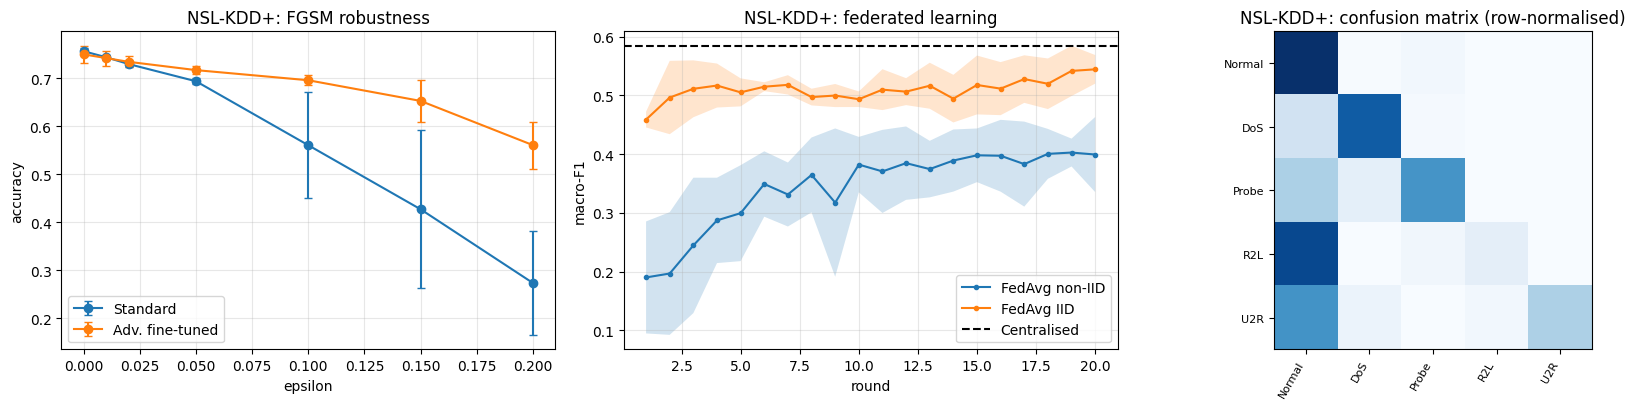

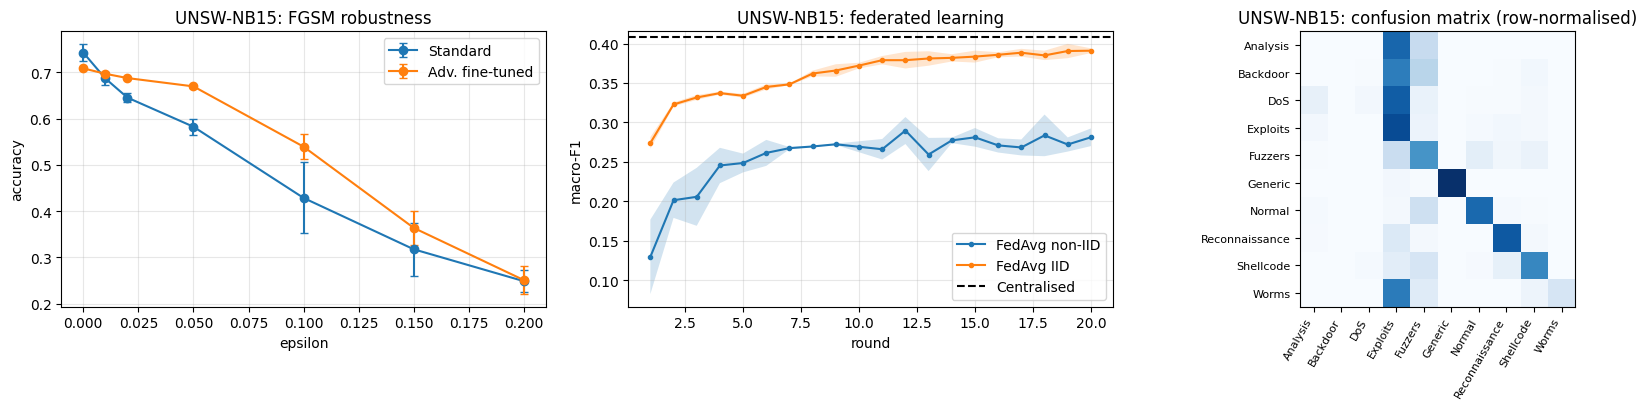

In [ ]:
# ===== Cell 11: figures =====
import matplotlib.pyplot as plt
for ds in df.dataset.unique():
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    # adversarial curve
    for mdl, lab in [("standard", "Standard"), ("adv_finetuned", "Adv. fine-tuned")]:
        g = dadv[(dadv.dataset == ds) & (dadv.model == mdl)].groupby("eps")["accuracy"]
        ax[0].errorbar(g.mean().index, g.mean().values, yerr=g.std().fillna(0).values, marker="o", capsize=3, label=lab)
    ax[0].set(title=f"{ds}: FGSM robustness", xlabel="epsilon", ylabel="accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
    # federated curve
    for part, lab in [("noniid", "FedAvg non-IID"), ("iid", "FedAvg IID")]:
        g = dfed[(dfed.dataset == ds) & (dfed.partition == part)].groupby("round")["macro_f1"]
        ax[1].plot(g.mean().index, g.mean().values, marker=".", label=lab)
        ax[1].fill_between(g.mean().index, (g.mean()-g.std().fillna(0)).values, (g.mean()+g.std().fillna(0)).values, alpha=.2)
    cen = df[(df.dataset == ds) & (df.method == "DeepGuard (cWGAN-GP)")].macro_f1.mean()
    ax[1].axhline(cen, color="k", ls="--", label="Centralised"); ax[1].set(title=f"{ds}: federated learning", xlabel="round", ylabel="macro-F1"); ax[1].legend(); ax[1].grid(alpha=.3)
    # confusion matrix (first seed)
    d = json.load(open(os.path.join(OUT, f"{ds}_seed{SEEDS[0]}.json")))
    cm = confusion_matrix(DATA[ds]["yte"], d["preds"]["DeepGuard (cWGAN-GP)"], labels=range(len(DATA[ds]["classes"])))
    cm = cm / cm.sum(1, keepdims=True).clip(1)
    ax[2].imshow(cm, cmap="Blues"); ax[2].set_xticks(range(len(cm))); ax[2].set_yticks(range(len(cm)))
    ax[2].set_xticklabels(DATA[ds]["classes"], rotation=60, ha="right", fontsize=8); ax[2].set_yticklabels(DATA[ds]["classes"], fontsize=8)
    ax[2].set(title=f"{ds}: confusion matrix (row-normalised)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT, f"fig_{ds}.png"), dpi=200); plt.show()

  0%|          | 0/120 [00:00<?, ?it/s]


NSL-KDD+ top-10 SHAP features:
 logged_in                      0.021918
dst_host_serror_rate           0.020365
flag                           0.019041
dst_host_rerror_rate           0.018843
dst_host_diff_srv_rate         0.015538
dst_host_srv_serror_rate       0.014398
dst_host_same_srv_rate         0.013700
protocol_type                  0.013314
service                        0.012982
dst_host_same_src_port_rate    0.012874
dtype: float64


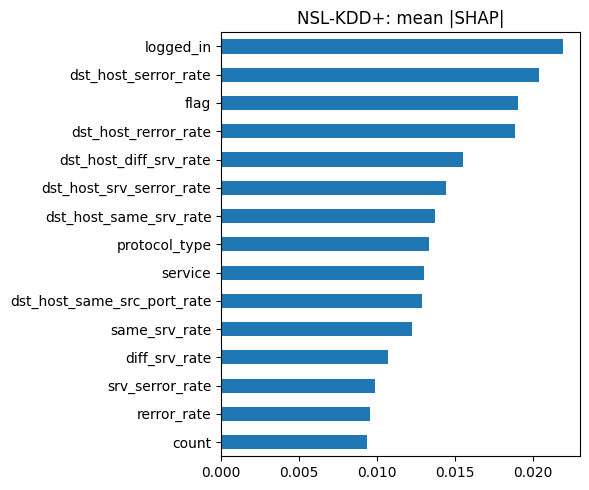

  0%|          | 0/120 [00:00<?, ?it/s]


UNSW-NB15 top-10 SHAP features:
 service           0.046200
sttl              0.027424
dttl              0.021454
state             0.017089
smean             0.013163
dwin              0.009131
ct_srv_dst        0.008101
swin              0.008026
rate              0.007882
ct_dst_src_ltm    0.007838
dtype: float64


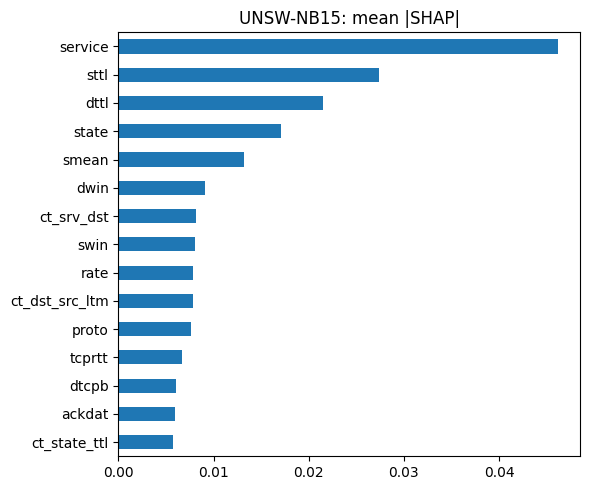

In [ ]:
# ===== Cell 12: SHAP (KernelSHAP, 40 background, 120 test instances, 100 coalitions – as in the paper) =====
import shap
def run_shap(name, D, seed):
    C = len(D["classes"]); m = DeepGuard(C).to(DEVICE)
    m.load_state_dict(torch.load(os.path.join(OUT, f"{name}_seed{seed}_main.pt"))); m.eval()
    rng = np.random.RandomState(0)
    bg = D["Xtr"][rng.choice(len(D["Xtr"]), 40, replace=False)]
    Xs = D["Xte"][rng.choice(len(D["Xte"]), 120, replace=False)]
    f = lambda a: predict_proba(m, torch.tensor(np.asarray(a), dtype=torch.float32, device=DEVICE))
    sv = shap.KernelExplainer(f, bg).shap_values(Xs, nsamples=100)
    if isinstance(sv, list): imp = np.mean([np.abs(s) for s in sv], axis=0)
    else:
        imp = np.abs(sv); imp = imp.mean(-1) if imp.ndim == 3 else imp
    imp = imp.mean(0)
    s = pd.Series(imp, index=D["features"]).sort_values(ascending=False)
    s.to_csv(os.path.join(OUT, f"shap_{name}.csv")); print(f"\n{name} top-10 SHAP features:\n", s.head(10))
    s.head(15)[::-1].plot.barh(figsize=(6, 5), title=f"{name}: mean |SHAP|"); plt.tight_layout()
    plt.savefig(os.path.join(OUT, f"fig_shap_{name}.png"), dpi=200); plt.show()

if RUN_SHAP:
    for name, D in DATA.items(): run_shap(name, D, SEEDS[0])

Binary view (benign = negative):
              tpr             fpr        
             mean     std    mean     std
dataset                                  
NSL-KDD+   0.6366  0.0368  0.0376  0.0236
UNSW-NB15  0.9884  0.0056  0.2835  0.0452

Per-class one-vs-rest TPR (recall) and FPR, mean over seeds:
                             tpr     fpr
dataset   cls                           
NSL-KDD+  DoS             0.8014  0.0227
          Normal          0.9624  0.3634
          Probe           0.5998  0.0219
          R2L             0.0900  0.0009
          U2R             0.3522  0.0009
UNSW-NB15 Analysis        0.0000  0.0096
          Backdoor        0.0000  0.0000
          DoS             0.0223  0.0023
          Exploits        0.8949  0.1195
          Fuzzers         0.5581  0.1171
          Generic         0.9618  0.0001
          Normal          0.7165  0.0116
          Reconnaissance  0.8015  0.0186
          Shellcode       0.5935  0.0097
          Worms           0.1061  0.000

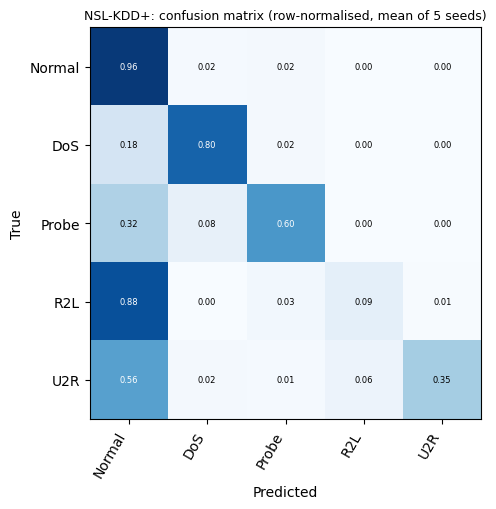

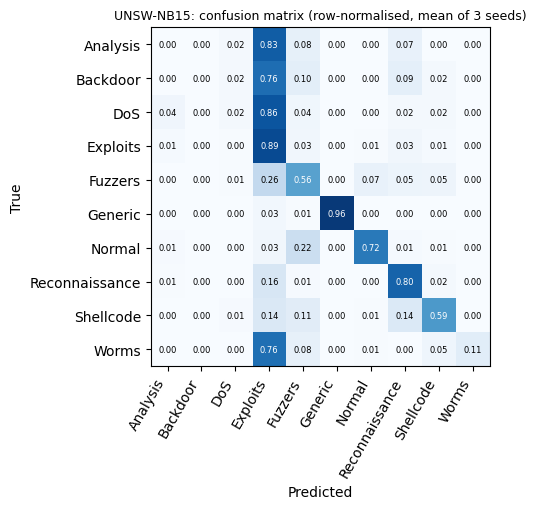

In [ ]:
SEEDS = [42, 43, 44, 45, 46]    # missing seeds are skipped automatically
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
rows, cms = [], []
for name, D in DATA.items():
    classes = D["classes"]; C = len(classes)
    neg = classes.index("Normal" if "Normal" in classes else "Benign")
    Xte_t = torch.tensor(D["Xte"], device=DEVICE); yte = D["yte"]
    cm_sum = np.zeros((C, C)); used = 0
    for seed in SEEDS:
        path = os.path.join(OUT, f"{name}_seed{seed}_main.pt")
        if not os.path.exists(path): continue
        m = DeepGuard(C).to(DEVICE); m.load_state_dict(torch.load(path, map_location=DEVICE)); m.eval()
        pred = predict_proba(m, Xte_t).argmax(1)
        cm = confusion_matrix(yte, pred, labels=list(range(C))); cm_sum += cm; used += 1
        neg_mask = (yte == neg)
        rows.append(dict(dataset=name, seed=seed, cls="BINARY (benign vs any attack)",
                         tpr=float((pred[~neg_mask] != neg).mean()),
                         fpr=float((pred[neg_mask] != neg).mean())))
        for c in range(C):
            tp = cm[c, c]; fp = cm[:, c].sum() - tp; tn = cm.sum() - cm[c, :].sum() - cm[:, c].sum() + tp
            rows.append(dict(dataset=name, seed=seed, cls=classes[c], tpr=float(tp / cm[c, :].sum()), fpr=float(fp / (fp + tn))))
    if used: cms.append((name, classes, cm_sum, used))
res = pd.DataFrame(rows)
print("Binary view (benign = negative):")
print(res[res.cls.str.startswith("BINARY")].groupby("dataset")[["tpr", "fpr"]].agg(["mean", "std"]).round(4))
print("\nPer-class one-vs-rest TPR (recall) and FPR, mean over seeds:")
print(res[~res.cls.str.startswith("BINARY")].groupby(["dataset", "cls"])[["tpr", "fpr"]].mean().round(4))
res.to_csv(os.path.join(OUT, "fpr_per_class.csv"), index=False)
for name, classes, cm, used in cms:
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=60, ha="right"); ax.set_yticklabels(classes)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"{name}: confusion matrix (row-normalised, mean of {used} seeds)", fontsize=9)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, f"confusion_{name}.png"), dpi=200); plt.show()

In [ ]:
# ===== Cell 14: class-weighted and tuned classical baselines (CPU only; resumable) =====
# Paste as a NEW cell at the end of EITHER notebook (NSL-KDD/UNSW notebook or NF-ToN-IoT notebook).
# Run Cells 1-4 first (imports, config, data loading, helpers). No GPU is needed: Runtime -> CPU is fine.
# It needs DATA, SEEDS, OUT and evaluate() from the notebook, and the per-seed *_seed*.json files in OUT.
# Results of each dataset are saved to OUT as soon as that dataset finishes; with RESUME = True a finished
# dataset is skipped, so a disconnect does not lose it. Use ONLY to run one dataset per cell run.
import itertools, json, os, time, warnings
import numpy as np, pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
warnings.filterwarnings("ignore")

ONLY = None                      # e.g. ["UNSW-NB15"] to run a single dataset; None = all datasets in DATA
RESUME = True                    # skip datasets already present in strong_baselines_raw.csv
SEEDS_DS = {"NSL-KDD+": [42, 43, 44, 45, 46]}          # seeds per dataset (others use SEEDS from the notebook)
TUNE_FRAC = {"Linear SVM (tuned)": 0.25}               # the SVM is tuned on a stratified 25% of the tuning set (speed)
RAW_CSV = os.path.join(OUT, "strong_baselines_raw.csv")

# 1) class-weighted but otherwise the paper's settings (untuned)
FIXED = {
    "Random Forest (balanced)":       lambda seed: RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1,
                                                    class_weight="balanced_subsample", random_state=seed),
    "Logistic Regression (balanced)": lambda seed: LogisticRegression(max_iter=300, class_weight="balanced"),
    "Linear SVM (balanced)":          lambda seed: LinearSVC(max_iter=2000, class_weight="balanced", random_state=seed),
}
# 2) small grids; class weighting is part of the grid. Selection by macro-F1 on a validation set.
GRIDS = {
    "Random Forest (tuned)": (lambda **k: RandomForestClassifier(n_estimators=100, n_jobs=-1, **k),
        dict(max_depth=[10, 20, None], min_samples_leaf=[1, 3], class_weight=[None, "balanced_subsample"])),
    "Logistic Regression (tuned)": (lambda **k: LogisticRegression(max_iter=500, **k),
        dict(C=[0.1, 1, 10], class_weight=[None, "balanced"])),
    "Linear SVM (tuned)": (lambda **k: LinearSVC(max_iter=1000, **k),
        dict(C=[0.1, 1], class_weight=[None, "balanced"])),
    "HistGradientBoosting (tuned)": (lambda **k: HistGradientBoostingClassifier(max_iter=300, early_stopping=True, **k),
        dict(max_leaf_nodes=[31, 63], class_weight=[None, "balanced"])),
}
DETERMINISTIC = ("Logistic Regression", "Linear SVM")  # fitted once, result reused for every seed

def _scores(m, X):
    return m.predict_proba(X) if hasattr(m, "predict_proba") else m.decision_function(X)

def _val_split(D):
    if "Xva" in D: return D["Xtr"], D["ytr"], D["Xva"], D["yva"]            # NF-ToN-IoT-v3 has a validation split
    Xa, Xv, ya, yv = train_test_split(D["Xtr"], D["ytr"], test_size=0.2, stratify=D["ytr"], random_state=42)
    return Xa, ya, Xv, yv                                                    # NSL-KDD+/UNSW-NB15: 80/20 of TRAIN only

def tune(name, D, C):
    make, grid = GRIDS[name]; Xa, ya, Xv, yv = _val_split(D); best = (-1.0, None); t0 = time.time()
    frac = TUNE_FRAC.get(name, 1.0)
    if frac < 1.0: Xa, _, ya, _ = train_test_split(Xa, ya, train_size=frac, stratify=ya, random_state=42)
    for vals in itertools.product(*grid.values()):
        kw = dict(zip(grid.keys(), vals)); m = make(**kw).set_params(random_state=42).fit(Xa, ya)
        f = f1_score(yv, _scores(m, Xv).argmax(1), average="macro", labels=list(range(C)), zero_division=0)
        if f > best[0]: best = (f, kw)
    print(f"  tuned {name}: {best[1]}  validation macro-F1 = {best[0]:.4f}  ({time.time() - t0:.0f}s)", flush=True)
    return best[1]

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); adj = np.zeros(len(p)); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

old = pd.read_csv(RAW_CSV) if (RESUME and os.path.exists(RAW_CSV)) else pd.DataFrame()
done = set(old.dataset.unique()) if len(old) else set()
rows = old.to_dict("records")
for name, D in DATA.items():
    if (ONLY is not None and name not in ONLY) or name in done:
        print(f"skip {name} ({'finished earlier' if name in done else 'not selected'})"); continue
    C, classes = len(D["classes"]), list(D["classes"]); Xtr, ytr, Xte, yte = D["Xtr"], D["ytr"], D["Xte"], D["yte"]
    nid = [i for i, c in enumerate(classes) if str(c).lower() in ("normal", "benign")][0]
    print(f"\n=== {name}: tuning on a validation set, then fitting on the training set ===", flush=True)
    best = {n: tune(n, D, C) for n in GRIDS}
    cache = {}; new_rows = []
    for seed in SEEDS_DS.get(name, SEEDS):
        models = {n: make(**best[n]).set_params(random_state=seed) for n, (make, _) in GRIDS.items()}
        models.update({n: f(seed) for n, f in FIXED.items()})
        for n, m in models.items():
            if n.startswith(DETERMINISTIC) and n in cache:
                r = dict(cache[n]); r["seed"] = seed; new_rows.append(r); continue
            t0 = time.time(); m.fit(Xtr, ytr); S = _scores(m, Xte); pred = S.argmax(1)
            r = evaluate(yte, pred, S, C); pcr = r.pop("per_class_recall")
            for k in ("per_class_precision", "per_class_f1"): r.pop(k)
            att = yte != nid
            r.update(dataset=name, seed=seed, method=n, detection_rate=float((pred[att] != nid).mean()),
                     false_alarm_rate=float((pred[~att] != nid).mean()), **{f"recall_{c}": v for c, v in zip(classes, pcr)})
            new_rows.append(r)
            if n.startswith(DETERMINISTIC): cache[n] = dict(r)
            print(f"  seed {seed} {n:30s} acc={r['accuracy']:.4f} macroF1={r['macro_f1']:.4f} FA={r['false_alarm_rate']:.3f} ({time.time() - t0:.0f}s)", flush=True)
    rows += new_rows; pd.DataFrame(rows).to_csv(RAW_CSV, index=False)      # saved as soon as this dataset is done
    print(f"saved {name} to {RAW_CSV}", flush=True)

raw = pd.DataFrame(rows)
def sd(x): return x.std(ddof=1)
summ = raw.groupby(["dataset", "method"])[["accuracy", "macro_f1", "mcc", "macro_auc", "detection_rate", "false_alarm_rate"]].agg(["mean", sd])
summ.to_csv(os.path.join(OUT, "strong_baselines_summary.csv")); print("\n=== mean and std over seeds ==="); display(summ.round(4))

# paired comparison with DeepGuard (same seeds, macro-F1); Holm over the new baselines within dataset and DeepGuard variant
def dg_f1(name, method):
    out = {}
    for s in SEEDS_DS.get(name, SEEDS):
        f = os.path.join(OUT, f"{name}_seed{s}.json")
        if os.path.exists(f):
            for r in json.load(open(f))["main"]:
                if r["method"] == method: out[s] = r["macro_f1"]
    return out

cmp_rows = []
for name in raw.dataset.unique():
    for dg in ["DeepGuard (no aug)", "DeepGuard (cWGAN-GP)"]:
        a = dg_f1(name, dg); block = []
        for n in raw[raw.dataset == name].method.unique():
            b = raw[(raw.dataset == name) & (raw.method == n)].set_index("seed").macro_f1.to_dict()
            seeds = sorted(set(a) & set(b))
            if len(seeds) < 3: continue
            x = np.array([a[s] for s in seeds]); y = np.array([b[s] for s in seeds]); d = x - y
            t = stats.t.ppf(0.975, len(d) - 1); h = t * d.std(ddof=1) / np.sqrt(len(d))
            block.append(dict(dataset=name, deepguard=dg, baseline=n, n_seeds=len(d), mean_diff=d.mean(), ci_low=d.mean() - h,
                              ci_high=d.mean() + h, d_z=d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else np.nan,
                              p=stats.ttest_rel(x, y).pvalue))
        if block:
            for r, pa in zip(block, holm([r["p"] for r in block])): r["p_holm"] = pa
            cmp_rows += block
cmp_df = pd.DataFrame(cmp_rows); cmp_df.to_csv(os.path.join(OUT, "strong_baselines_vs_deepguard.csv"), index=False)
print("\n=== DeepGuard minus baseline (macro-F1, paired over seeds) ==="); display(cmp_df.round(4))

skip NSL-KDD+ (finished earlier)
skip UNSW-NB15 (finished earlier)

=== mean and std over seeds ===


accuracy         macro_f1             mcc         macro_auc         detection_rate         false_alarm_rate        
                                             mean      sd     mean      sd    mean      sd      mean      sd           mean      sd             mean      sd
dataset   method                                                                                                                                            
NSL-KDD+  HistGradientBoosting (tuned)     0.7742  0.0061   0.6064  0.0116  0.6747  0.0085    0.9268  0.0088         0.6634  0.0182           0.0297  0.0005
          Linear SVM (balanced)            0.7450  0.0000   0.5235  0.0000  0.6255  0.0000    0.8999  0.0000         0.6622  0.0000           0.0672  0.0000
          Linear SVM (tuned)               0.7451  0.0000   0.5515  0.0000  0.6305  0.0000    0.8982  0.0000         0.6083  0.0000           0.0401  0.0000
          Logistic Regression (balanced)   0.7937  0.0000   0.6078  0.0000  0.7016  0.0000    0.9206  0.0000         0.7464  0.0000           0.0566  0.0000
          Logistic Regression (tuned)      0.7602  0.0000   0.5570  0.0000  0.6567  0.0000    0.9123  0.0000         0.6200  0.0000           0.0244  0.0000
          Random Forest (balanced)         0.7385  0.0020   0.4837  0.0033  0.6230  0.0029    0.9109  0.0096         0.5795  0.0044           0.0276  0.0008
          Random Forest (tuned)            0.7385  0.0020   0.4837  0.0033  0.6230  0.0029    0.9109  0.0096         0.5795  0.0044           0.0276  0.0008
UNSW-NB15 HistGradientBoosting (tuned)     0.6795  0.0013   0.5005  0.0030  0.6189  0.0013    0.9592  0.0006         0.9959  0.0009           0.3972  0.0028
          Linear SVM (balanced)            0.6324  0.0000   0.3533  0.0000  0.5583  0.0000    0.9115  0.0000         0.9977  0.0000           0.4245  0.0000
          Linear SVM (tuned)               0.6324  0.0000   0.3533  0.0000  0.5583  0.0000    0.9115  0.0000         0.9977  0.0000           0.4245  0.0000
          Logistic Regression (balanced)   0.5921  0.0000   0.3215  0.0000  0.5132  0.0000    0.9211  0.0000         0.9900  0.0000           0.4236  0.0000
          Logistic Regression (tuned)      0.6703  0.0000   0.3258  0.0000  0.5819  0.0000    0.9178  0.0000         0.9443  0.0000           0.3704  0.0000
          Random Forest (balanced)         0.6857  0.0014   0.4961  0.0038  0.6218  0.0018    0.9502  0.0008         0.9897  0.0016           0.3868  0.0020
          Random Forest (tuned)            0.6857  0.0014   0.4961  0.0038  0.6218  0.0018    0.9502  0.0008         0.9897  0.0016           0.3868  0.0020


=== DeepGuard minus baseline (macro-F1, paired over seeds) ===


,dataset,deepguard,baseline,n_seeds,mean_diff,ci_low,ci_high,d_z,p,p_holm
0,NSL-KDD+,DeepGuard (no aug),Random Forest (tuned),5,0.0829,0.0464,0.1194,2.8173,0.0032,0.0227
1,NSL-KDD+,DeepGuard (no aug),Logistic Regression (tuned),5,0.0096,-0.0290,0.0481,0.3080,0.5289,0.6785
2,NSL-KDD+,DeepGuard (no aug),Linear SVM (tuned),5,0.0151,-0.0235,0.0536,0.4849,0.3393,0.6785
3,NSL-KDD+,DeepGuard (no aug),HistGradientBoosting (tuned),5,-0.0398,-0.0789,-0.0007,-1.2645,0.0475,0.1808
4,NSL-KDD+,DeepGuard (no aug),Random Forest (balanced),5,0.0829,0.0464,0.1194,2.8173,0.0032,0.0227
5,NSL-KDD+,DeepGuard (no aug),Logistic Regression (balanced),5,-0.0412,-0.0798,-0.0027,-1.3276,0.0412,0.1808
6,NSL-KDD+,DeepGuard (no aug),Linear SVM (balanced),5,0.0431,0.0045,0.0816,1.3872,0.0362,0.1808
7,NSL-KDD+,DeepGuard (cWGAN-GP),Random Forest (tuned),5,0.1000,0.0822,0.1178,6.9846,0.0001,0.0007
8,NSL-KDD+,DeepGuard (cWGAN-GP),Logistic Regression (tuned),5,0.0267,0.0049,0.0484,1.5196,0.0273,0.0820
9,NSL-KDD+,DeepGuard (cWGAN-GP),Linear SVM (tuned),5,0.0321,0.0104,0.0539,1.8327,0.0149,0.0595


In [ ]:
class DGAblation(nn.Module):
    def __init__(self, C, cnn=True, lstm=True, attn=True):
        super().__init__()
        self.cnn, self.lstm_on, self.attn_on = cnn, lstm, attn
        if cnn:
            self.c1 = nn.Conv1d(1, 16, 3, padding=1)
            self.c2 = nn.Conv1d(16, 32, 3, padding=2, dilation=2); self.b2 = nn.BatchNorm1d(32)
            self.c3 = nn.Conv1d(32, 64, 3, padding=2, dilation=2); self.b3 = nn.BatchNorm1d(64)
            self.proj = nn.Conv1d(16, 64, 1)
        d_in = 64 if cnn else 1
        if lstm:
            self.lstm = nn.LSTM(d_in, 24, batch_first=True, bidirectional=True); d = 48
        else:
            d = d_in
        if attn:
            self.attn = nn.MultiheadAttention(d, 4 if d % 4 == 0 else 1, batch_first=True); self.ln = nn.LayerNorm(d)
        self.fc1 = nn.Linear(d, 64); self.drop = nn.Dropout(0.3); self.fc2 = nn.Linear(64, C)
    def forward(self, x):
        x = x.unsqueeze(1)
        if self.cnn:
            h1 = F.relu(self.c1(x)); h2 = F.relu(self.b2(self.c2(h1)))
            h = F.relu(self.b3(self.c3(h2) + self.proj(h1))).transpose(1, 2)
        else:
            h = x.transpose(1, 2)
        if self.lstm_on: h, _ = self.lstm(h)
        if self.attn_on:
            a, _ = self.attn(h, h, h); h = self.ln(h + a)
        return self.fc2(self.drop(F.relu(self.fc1(h.mean(1)))))

VARIANTS = {"full": (True, True, True), "no attention": (True, True, False),
            "no BiLSTM": (True, False, True), "no CNN": (False, True, True)}
rows = []
for name, D in DATA.items():
    if name.startswith("UNSW"): continue
    C = len(D["classes"]); w = class_weights(D["ytr"], C)
    Xtr_t = torch.tensor(D["Xtr"], device=DEVICE); ytr_t = torch.tensor(D["ytr"], device=DEVICE)
    Xte_t = torch.tensor(D["Xte"], device=DEVICE)
    kw = dict(val=(torch.tensor(D["Xva"], device=DEVICE), D["yva"])) if "Xva" in D else {}
    for seed in SEEDS:
        for vname, (a, b, c) in VARIANTS.items():
            set_seed(seed)
            m = DGAblation(C, a, b, c).to(DEVICE)
            train_model(m, Xtr_t, ytr_t, EPOCHS, w=w, tag=vname, verbose=False, **kw)
            pred = predict_proba(m, Xte_t).argmax(1)
            rows.append(dict(dataset=name, seed=seed, variant=vname, params=sum(p.numel() for p in m.parameters()),
                             accuracy=float(accuracy_score(D["yte"], pred)),
                             macro_f1=float(f1_score(D["yte"], pred, average="macro", labels=list(range(C)), zero_division=0))))
        print("done", name, seed)
abl = pd.DataFrame(rows)
print(abl.groupby(["dataset", "variant"])[["params", "accuracy", "macro_f1"]].agg(["mean", "std"]).round(4))
abl.to_csv(os.path.join(OUT, "architecture_ablation.csv"), index=False)

done NSL-KDD+ 42
done NSL-KDD+ 43
done NSL-KDD+ 44
done NSL-KDD+ 45
done NSL-KDD+ 46
                        params      accuracy         macro_f1        
                          mean  std     mean     std     mean     std
dataset  variant                                                     
NSL-KDD+ full          39365.0  0.0   0.7439  0.0153   0.5515  0.0228
         no BiLSTM     30373.0  0.0   0.7525  0.0130   0.5443  0.0365
         no CNN        18149.0  0.0   0.7485  0.0080   0.5525  0.0321
         no attention  29861.0  0.0   0.7526  0.0070   0.5342  0.0373
